# 02 · Pré-processamento, duplicatas e vazamento de dados
Decide, com evidência, o que entra no pipeline final. Princípio: **tudo que aprende dos dados** (padronização, Yeo-Johnson, medianas)
fica dentro de um `Pipeline` e é ajustado só no treino de cada dobra.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":      # funciona rodando de notebooks/ ou da raiz do repositório
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import config, eda
from src.preprocessing import carregar_dados, criar_alvo, NOMES_PT

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CAMINHO = config.resolve_data_path()
print("BASE USADA:", CAMINHO.name, "" if config.is_official(CAMINHO) else
      f"  <-- ATENÇÃO: não é a base oficial ({config.OFFICIAL_DATASET}); execução de ENSAIO")
df = carregar_dados(CAMINHO)
config.ensure_dirs()
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from scipy import stats
from src.preprocessing import (LogAssimetricas, FeaturesEnologicas, COLUNAS_ASSIMETRICAS,
                               contar_vazamento_duplicatas, remover_duplicatas)
RS = config.RANDOM_STATE
X, y = criar_alvo(df)

BASE USADA: WineQT.csv 


## 1. Dados faltantes
O desafio pede tratar faltantes *se houver*. Verificamos e **não** criamos etapa de imputação desnecessária.

In [2]:
print("Valores faltantes:", int(df.isna().sum().sum()))

Valores faltantes: 0


## 2. Duplicatas e vazamento treino→teste
Linhas 100% idênticas podem cair uma no treino e outra no teste: o modelo seria avaliado em algo que já viu.
**Ressalva:** os valores são arredondados, então vinhos *diferentes* podem coincidir; não dá para provar que são erros. Por isso a decisão é acompanhada de análise de sensibilidade (notebook 03).

In [3]:
n_dup = int(df.duplicated().sum())
print(f"Duplicatas exatas: {n_dup} ({n_dup/len(df):.1%})")
Xa, Xb, ya, yb = train_test_split(X, y, test_size=.2, stratify=y, random_state=RS)
v = contar_vazamento_duplicatas(Xa, Xb)
print(f"Split SEM remover duplicatas: {v} de {len(Xb)} linhas do teste ({v/len(Xb):.1%}) têm cópia exata no treino")
df_sd = remover_duplicatas(df)
Xs, ys = criar_alvo(df_sd)
Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=.2, stratify=ys, random_state=RS)
print(f"Split APÓS remover duplicatas: {contar_vazamento_duplicatas(Xa, Xb)} linhas de teste com cópia no treino")
X, y = Xs, ys   # a partir daqui, base sem duplicatas (decisão documentada no README)

Duplicatas exatas: 125 (10.9%)
Split SEM remover duplicatas: 34 de 229 linhas do teste (14.8%) têm cópia exata no treino
Duplicatas removidas: 125 de 1143 (10.9%) -> 1018 linhas
Split APÓS remover duplicatas: 0 linhas de teste com cópia no treino


## 3. Assimetria e outliers
Mede quais variáveis têm cauda longa. Outliers **não** são removidos (podem ser reais).

In [4]:
assim = X.skew().sort_values(ascending=False).round(2)
q1, q3 = X.quantile(.25), X.quantile(.75); iqr = q3 - q1
pct = (((X < q1 - 1.5*iqr) | (X > q3 + 1.5*iqr)).mean()*100).round(1)
display(pd.DataFrame({"assimetria": assim, "% outliers IQR": pct.reindex(assim.index)}))
colunas_skew = [c for c in assim.index if assim[c] > 1]
print("Colunas com assimetria > 1 nesta base:", colunas_skew)
print("COLUNAS_ASSIMETRICAS em src/preprocessing.py:", COLUNAS_ASSIMETRICAS)

,assimetria,% outliers IQR
chlorides,5.93,7.0
residual_sugar,4.35,9.3
sulphates,2.42,4.0
total_sulfur_dioxide,1.68,3.2
free_sulfur_dioxide,1.17,1.6
fixed_acidity,1.04,3.6
alcohol,0.85,0.6
volatile_acidity,0.72,1.0
citric_acid,0.37,0.1
ph,0.26,2.4


Colunas com assimetria > 1 nesta base: ['chlorides', 'residual_sugar', 'sulphates', 'total_sulfur_dioxide', 'free_sulfur_dioxide', 'fixed_acidity']
COLUNAS_ASSIMETRICAS em src/preprocessing.py: ['chlorides', 'residual_sugar', 'sulphates', 'total_sulfur_dioxide', 'free_sulfur_dioxide']


## 4. log(1+x) × Yeo-Johnson
Para valores pequenos (cloretos ≈ 0,08), `log(1+x) ≈ x` e quase não corrige a assimetria. *Nota:* aqui o ajuste é feito na base inteira **apenas para descrever**; no modelo, o ajuste ocorre dentro do Pipeline.

In [5]:
X_log = LogAssimetricas().fit(X).transform(X)
X_yj = pd.DataFrame(PowerTransformer().fit_transform(X), columns=X.columns)
cols = [c for c in COLUNAS_ASSIMETRICAS if c in X.columns]
display(pd.DataFrame({"original": X[cols].skew(), "log(1+x)": X_log[cols].skew(), "Yeo-Johnson": X_yj[cols].skew()}).round(2))

,original,log(1+x),Yeo-Johnson
chlorides,5.93,5.27,-0.12
residual_sugar,4.35,2.11,-0.00
sulphates,2.42,1.65,0.01
total_sulfur_dioxide,1.68,-0.02,-0.00
free_sulfur_dioxide,1.17,-0.09,-0.01


## 5. Demonstração de vazamento no ajuste do scaler
Ajustar o padronizador em **todos** os dados (antes do split) usa informação do teste. O efeito costuma ser pequeno, mas o procedimento correto é gratuito.

In [6]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=RS)
d = pd.DataFrame({"desvio_fit_tudo": X.std(), "desvio_fit_treino": Xtr.std()})
d["diferenca_%"] = ((d.desvio_fit_tudo/d.desvio_fit_treino-1)*100).round(2)
display(d.reindex(d["diferenca_%"].abs().sort_values(ascending=False).index).round(4).head(6))

,desvio_fit_tudo,desvio_fit_treino,diferenca_%
residual_sugar,1.3149,1.1926,10.25
chlorides,0.0485,0.0518,-6.45
sulphates,0.1675,0.1752,-4.36
total_sulfur_dioxide,33.1235,33.8238,-2.07
ph,0.1578,0.1601,-1.46
alcohol,1.0951,1.0803,1.36


## 6. Qual pré-processamento para qual modelo? (CV 5×3 repetida, ROC-AUC, scaler **dentro** do Pipeline)
Diferenças de CV repetida não são independentes: p-valores abaixo são **otimistas**; interprete principalmente o `delta` e o `% de folds vencidos`.

In [7]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
def lr(prep): return Pipeline(prep + [("clf", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=RS))])
def rf(prep): return Pipeline(prep + [("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RS, n_jobs=1))])
cenarios = {
 "LogReg": {
   "A. StandardScaler":           lr([("s", StandardScaler())]),
   "B. log(assim.)+StandardScaler": lr([("l", LogAssimetricas()), ("s", StandardScaler())]),
   "C. Yeo-Johnson":              lr([("p", PowerTransformer())]),
   "D. Yeo-Johnson + features novas": lr([("f", FeaturesEnologicas()), ("p", PowerTransformer())]),
 },
 "RandomForest": {
   "A. sem transformação":        rf([("pass", "passthrough")]),
   "C. Yeo-Johnson":              rf([("p", PowerTransformer())]),
   "D. features novas":           rf([("f", FeaturesEnologicas())]),
 }}
notas = {}
for m, cs in cenarios.items():
    for nome, pipe in cs.items():
        notas[(m, nome)] = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
linhas = []
for m, cs in cenarios.items():
    base = notas[(m, list(cs)[0])]
    for nome in cs:
        s = notas[(m, nome)]
        linhas.append({"modelo": m, "cenario": nome, "ROC-AUC": s.mean(), "dp": s.std(ddof=1),
                       "delta vs A": (s-base).mean(), "% folds melhores": (s > base).mean()*100,
                       "p (Wilcoxon, otimista)": stats.wilcoxon(s, base).pvalue if nome != list(cs)[0] and not np.allclose(s, base) else np.nan})
res = pd.DataFrame(linhas); display(res.round(4))
res.to_csv(config.RESULTS_DIR / "preprocessamento_ab.csv", index=False)

,modelo,cenario,ROC-AUC,dp,delta vs A,% folds melhores,"p (Wilcoxon, otimista)"
0,LogReg,A. StandardScaler,0.8806,0.0340,0.0000,0.0000,NaN
1,LogReg,B. log(assim.)+StandardScaler,0.8824,0.0350,0.0017,73.3333,0.0735
2,LogReg,C. Yeo-Johnson,0.8877,0.0318,0.0071,73.3333,0.0151
3,LogReg,D. Yeo-Johnson + features novas,0.8891,0.0324,0.0085,86.6667,0.0006
4,RandomForest,A. sem transformação,0.8837,0.0306,0.0000,0.0000,NaN
5,RandomForest,C. Yeo-Johnson,0.8837,0.0292,-0.0001,66.6667,0.6788
6,RandomForest,D. features novas,0.8851,0.0310,0.0014,66.6667,0.3303


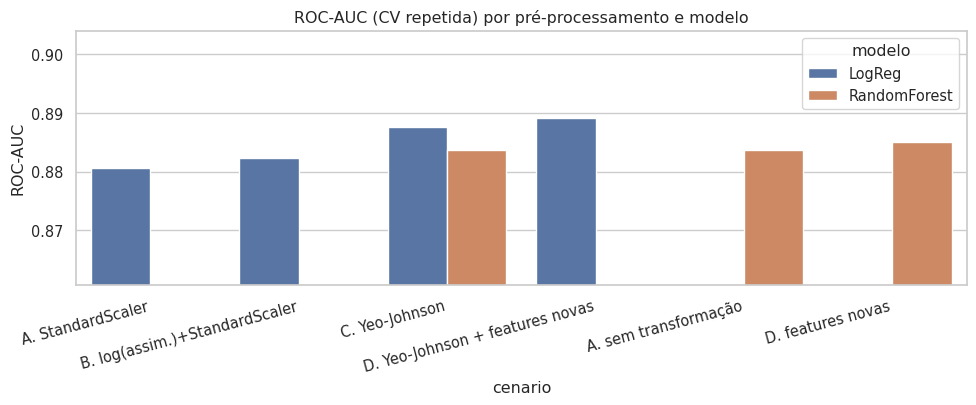

In [8]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=res, x="cenario", y="ROC-AUC", hue="modelo", ax=ax)
ax.set_ylim(res["ROC-AUC"].min()-0.02, res["ROC-AUC"].max()+0.015)
ax.set_title("ROC-AUC (CV repetida) por pré-processamento e modelo"); plt.xticks(rotation=15, ha="right")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "05_ab_preprocessamento.png", dpi=150); plt.show()

## 7. Decisões (geradas dos números acima)

In [9]:
g = lambda m, c: res[(res.modelo==m)&(res.cenario==c)].iloc[0]
d_lr_yj = g("LogReg","C. Yeo-Johnson")["delta vs A"]; d_lr_fe = g("LogReg","D. Yeo-Johnson + features novas")["delta vs A"] - d_lr_yj
d_rf_yj = g("RandomForest","C. Yeo-Johnson")["delta vs A"]; d_rf_fe = g("RandomForest","D. features novas")["delta vs A"]
LIM = 0.002   # diferença mínima de ROC-AUC para considerar relevante
esc_yj = "Adotar (somente perfil linear)" if d_lr_yj > LIM else "Efeito desprezível nesta base: manter só no perfil linear (padroniza; não prejudica)"
esc_fe_l = "Não adotar: ganho marginal e redundância com variáveis existentes" if d_lr_fe <= LIM else "Ganho relevante: avaliar adoção (reportar no README)"
esc_fe_r = "Não adotar" if d_rf_fe <= LIM else "Ganho relevante: avaliar adoção (reportar no README)"
display(Markdown(f'''| Decisão | Evidência nesta base | Escolha |
|---|---|---|
| Yeo-Johnson para modelos lineares | Δ ROC-AUC vs StandardScaler = {d_lr_yj:+.4f} | {esc_yj} |
| Yeo-Johnson para árvores | Δ vs sem transformação = {d_rf_yj:+.4f} | Não aplicar (árvores usam limiares: transformação monotônica não muda os cortes) |
| Features enológicas (linear) | ganho adicional sobre Yeo-Johnson = {d_lr_fe:+.4f} | {esc_fe_l} |
| Features enológicas (Random Forest) | Δ vs sem transformação = {d_rf_fe:+.4f} | {esc_fe_r} |
| Duplicatas | ver bloco 2 e sensibilidade no notebook 03 | Remover antes do split e reportar os dois cenários |
| Faltantes / outliers | 0 faltantes; outliers plausíveis | Nada a imputar; outliers mantidos |'''))

| Decisão | Evidência nesta base | Escolha |
|---|---|---|
| Yeo-Johnson para modelos lineares | Δ ROC-AUC vs StandardScaler = +0.0071 | Adotar (somente perfil linear) |
| Yeo-Johnson para árvores | Δ vs sem transformação = -0.0001 | Não aplicar (árvores usam limiares: transformação monotônica não muda os cortes) |
| Features enológicas (linear) | ganho adicional sobre Yeo-Johnson = +0.0014 | Não adotar: ganho marginal e redundância com variáveis existentes |
| Features enológicas (Random Forest) | Δ vs sem transformação = +0.0014 | Não adotar |
| Duplicatas | ver bloco 2 e sensibilidade no notebook 03 | Remover antes do split e reportar os dois cenários |
| Faltantes / outliers | 0 faltantes; outliers plausíveis | Nada a imputar; outliers mantidos |